In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import sys
from pathlib import Path

SEED = 987

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))


%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
import data

df = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

/home/koyo-ai/miniconda3/envs/homeless/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Visualizations TODO:
- Plot Mean Prices per day over time
- Plot mean prices per day over time separated by categorical features

In [6]:
df["month"] = df["date_listed"].dt.month
df["year"] = df["date_listed"].dt.year
df["day"] = df["date_listed"].dt.day
df["days_since_2021"] = (df["date_listed"] - pd.Timestamp("2021-01-01")).dt.days

time_features = ['month', 'year', 'day', 'days_since_2021']

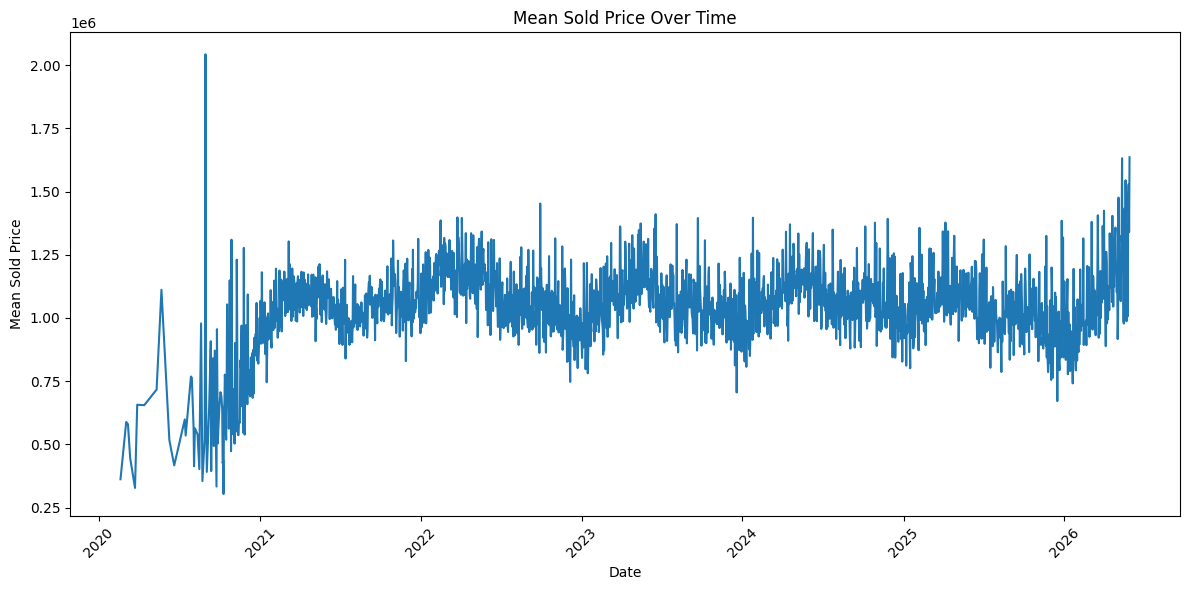

In [7]:
daily_mean = df.groupby(df["date_listed"])["sold_price"].mean()

plt.figure(figsize=(12, 6))
plt.plot(daily_mean.index, daily_mean.values)
plt.xlabel("Date")
plt.ylabel("Mean Sold Price")
plt.title("Mean Sold Price Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

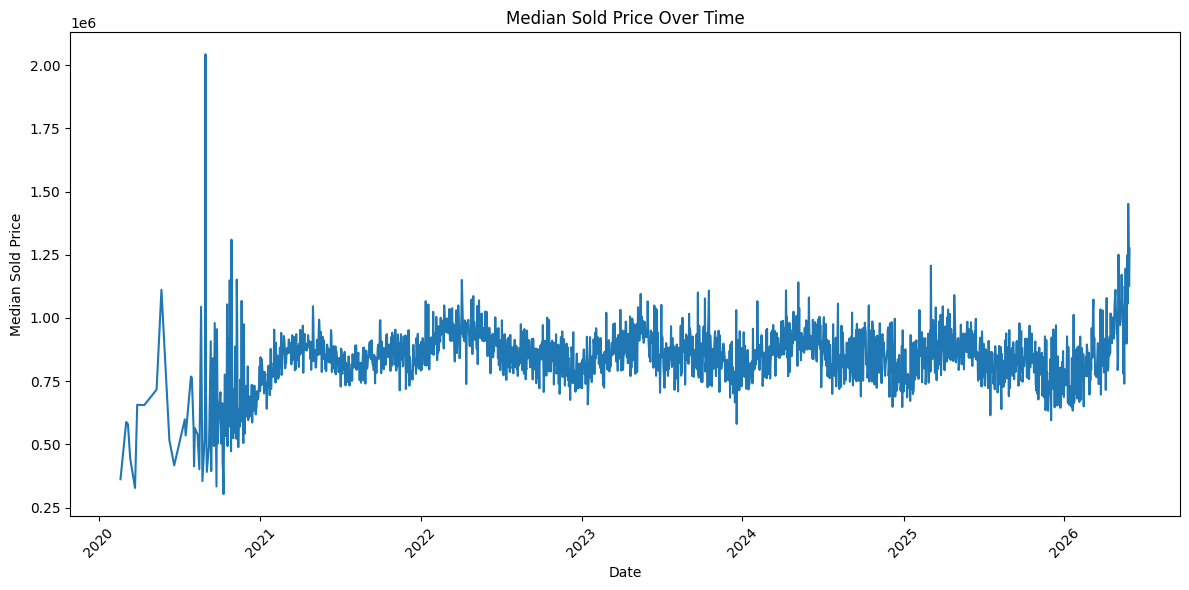

In [8]:
daily_median = df.groupby(df["date_listed"])["sold_price"].median()

plt.figure(figsize=(12, 6))
plt.plot(daily_median.index, daily_median.values)
plt.xlabel("Date")
plt.ylabel("Median Sold Price")
plt.title("Median Sold Price Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

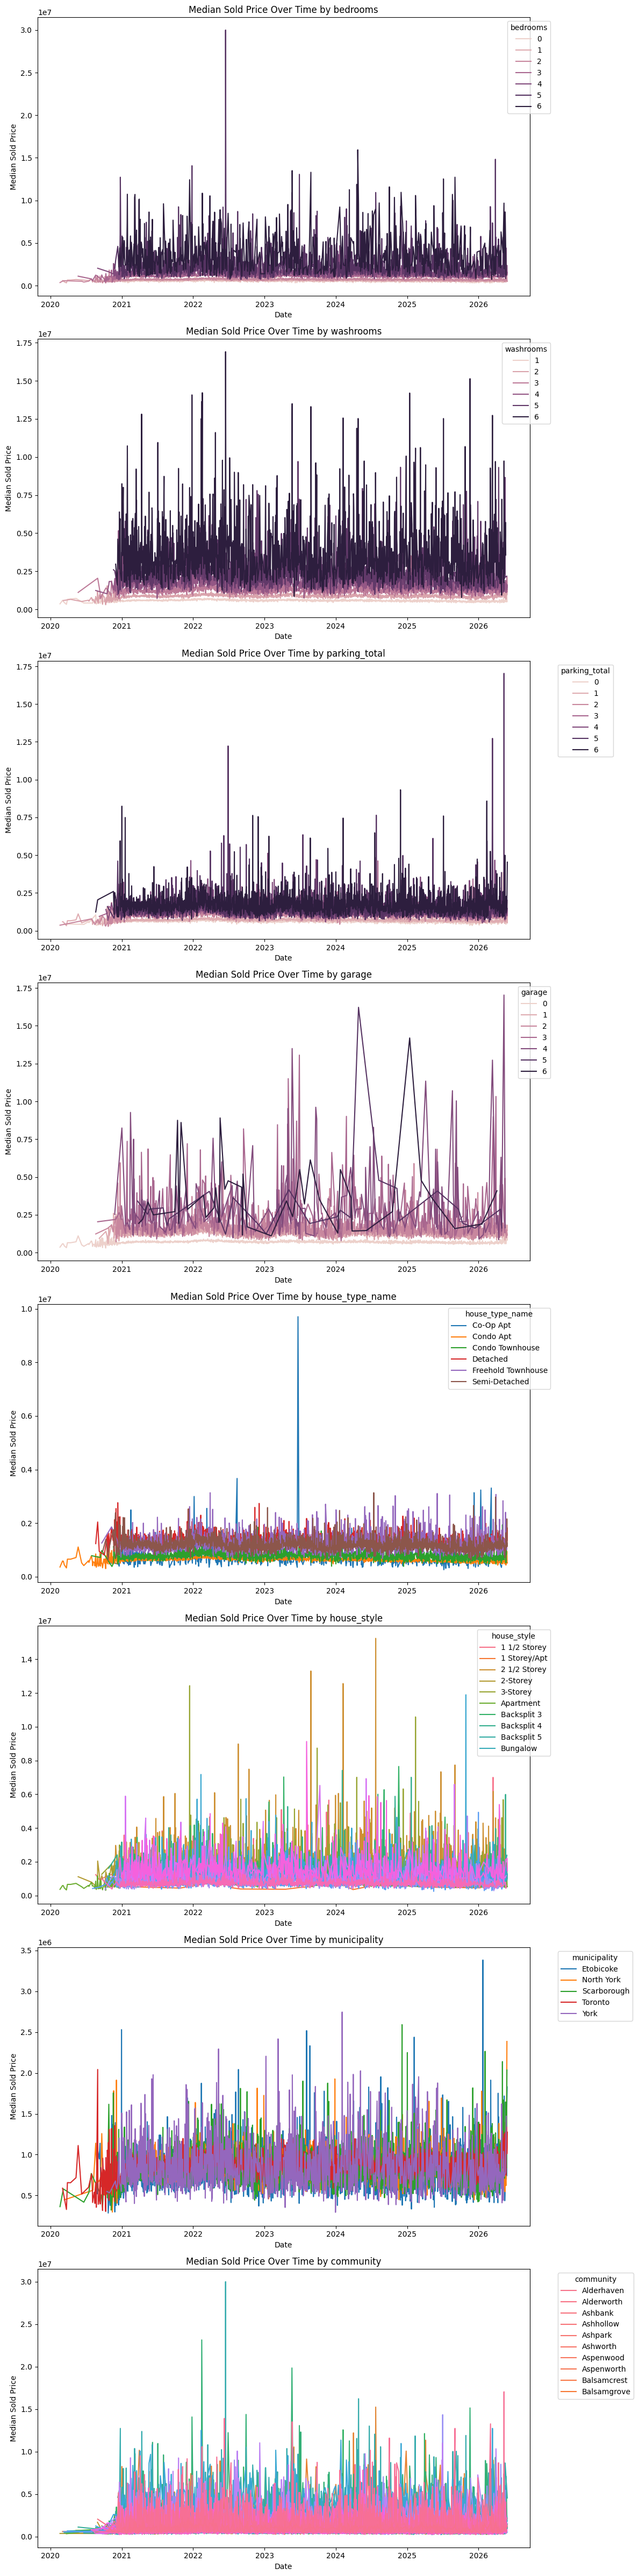

In [9]:
# Sold Price Over Time Grouped By Categorical Features
categorical_features = ['bedrooms', 'washrooms', 'parking_total', 'garage', 'house_type_name', 'house_style', 'municipality', 'community']

fig, axes = plt.subplots(len(categorical_features), 1, figsize=(12, 6 * len(categorical_features)))
axes = axes.flatten()

for i, feature in enumerate(categorical_features):
    grouped = df.groupby([feature, 'date_listed'])['sold_price'].median().reset_index()
    sns.lineplot(data=grouped, x='date_listed', y='sold_price', hue=feature, ax=axes[i])
    axes[i].set_title(f'Median Sold Price Over Time by {feature}')
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('Median Sold Price')
    handles, labels = axes[i].get_legend_handles_labels()
    axes[i].legend(handles[:10], labels[:10], title=feature, bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

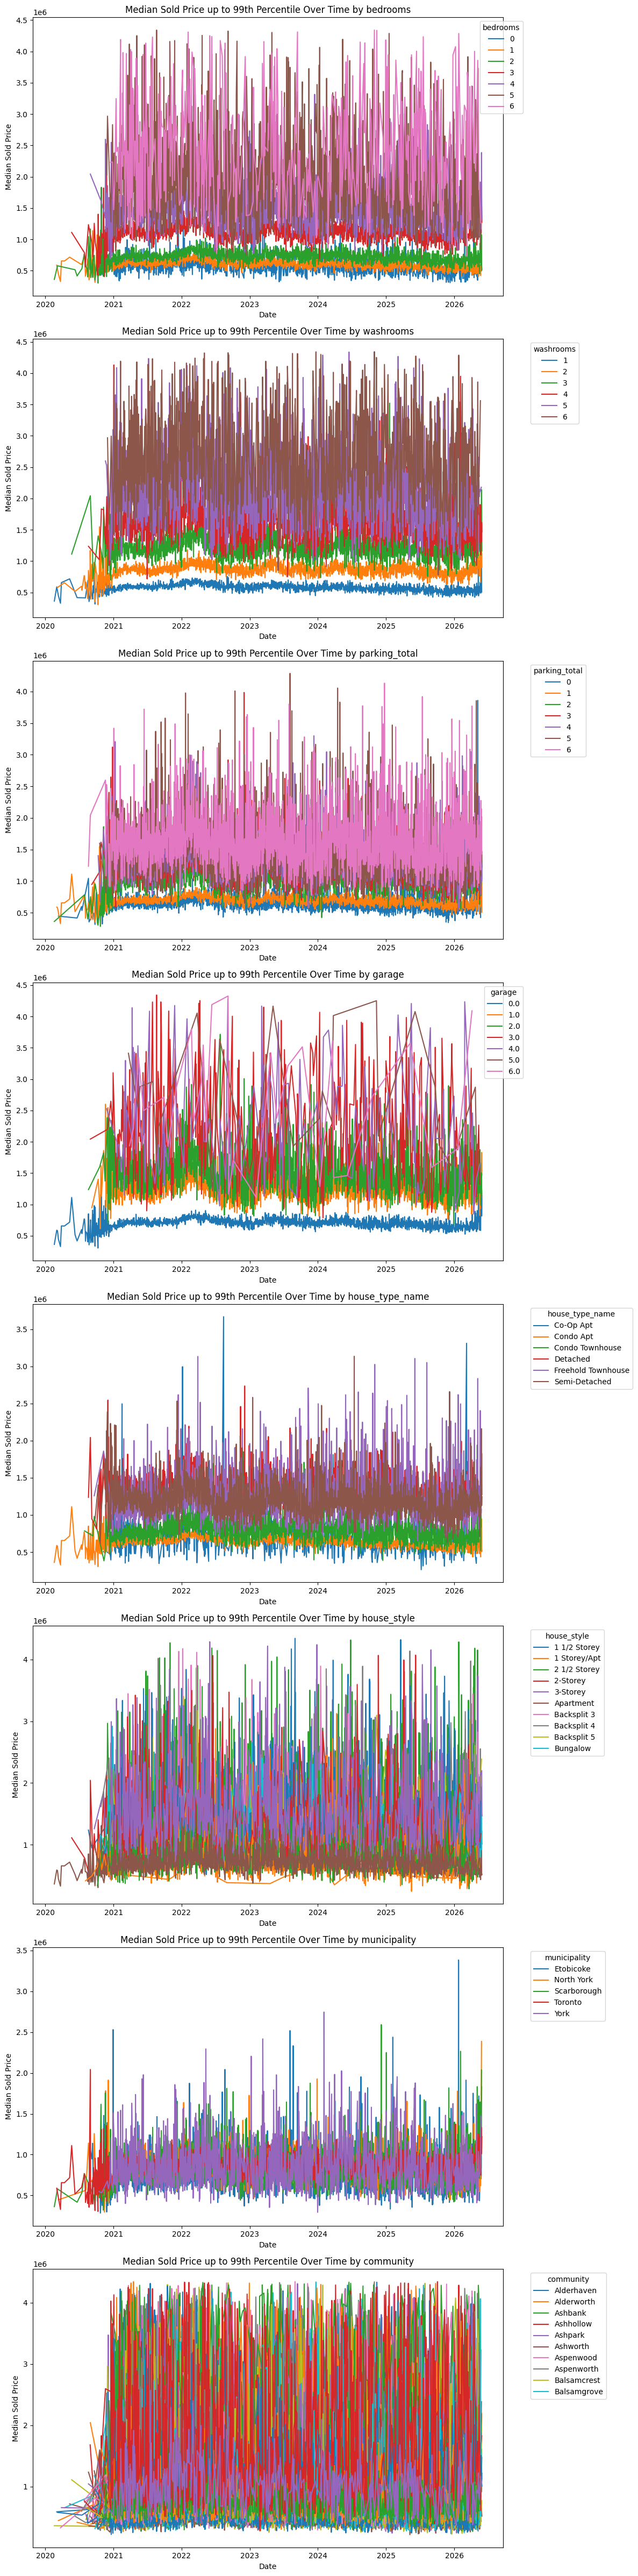

In [10]:
# Reduced Outliers so i can actually see what is going on
fig, axes = plt.subplots(len(categorical_features), 1, figsize=(12, 6 * len(categorical_features)))
axes = axes.flatten()

sold_price_threshold = df['sold_price'].quantile(0.99)

for i, feature in enumerate(categorical_features):
    grouped = df[df['sold_price'] <= sold_price_threshold].groupby([feature, 'date_listed'])['sold_price'].median().reset_index()
    sns.lineplot(data=grouped, x='date_listed', y='sold_price', palette='tab10', hue=feature, ax=axes[i])
    axes[i].set_title(f'Median Sold Price up to 99th Percentile Over Time by {feature}')
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('Median Sold Price')
    handles, labels = axes[i].get_legend_handles_labels()
    axes[i].legend(handles[:10], labels[:10], title=feature, bbox_to_anchor=(1.05, 1))

plt.tight_layout()
plt.show()

## What the Freaky Weaky Smeaky Does This Mean
- bedrooms, yeah there is decent difference in sold price by bedrooms. It appears that for the higher bedroom houses there is massive variation in the price even when considering for median instead of mean.
- Washrooms have similar Trend as bedrooms with houses that have lots of washrooms also having very high variation in the washroom prices.
- Parking totals similar to previous features.
- Garage also kinda similar. THere is a very clear cyclical trend for 2.0 and 1.0 garages. It appears that super rich people don't follow conventional logic and super poor people also dont (or its just apartments with 0 garages)
- House type yeah theres some decent separation
- Idk what the hell is going on with house style
- I don't see much different between municipalities, except that variance appears to be fairly difference between municipalities, this might be due to sample size (Toronto has a lot more samples than everything else so its more stable?)
- I don't want to look at community

In [11]:
def is_house_apartment(row):
    if row["house_type_name"] in ["Co-op Apt", "Condo Apt", "Condo Townhouse"]:
        return 1
    else:
        return 0

df["is_apartment"] = df.apply(is_house_apartment, axis=1)

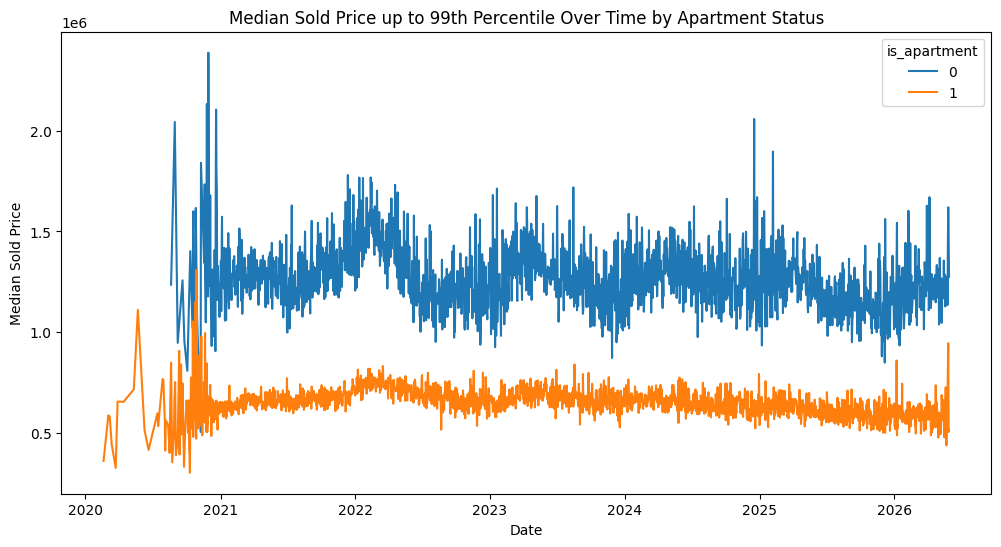

In [12]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=df[df['sold_price'] <= sold_price_threshold].groupby(['is_apartment', 'date_listed'])['sold_price'].median().reset_index(), x='date_listed', y='sold_price', hue='is_apartment')
plt.title('Median Sold Price up to 99th Percentile Over Time by Apartment Status')
plt.xlabel('Date')
plt.ylabel('Median Sold Price')
plt.show()

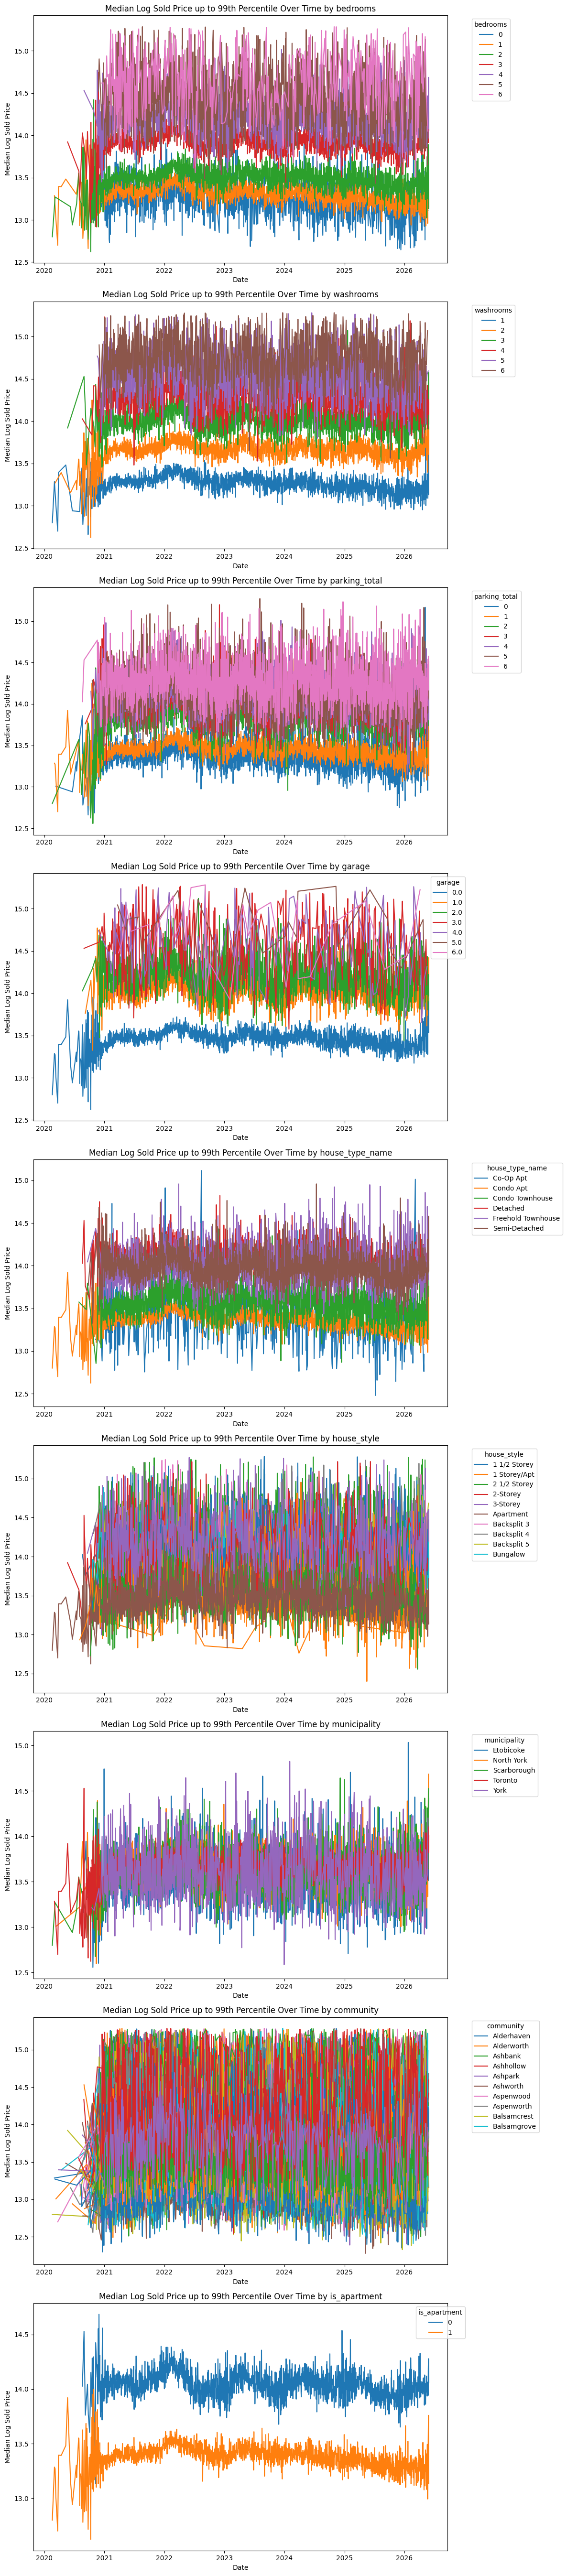

In [13]:
# Median Log Sold Price Over Time by various features
categorical_features_with_apartment = categorical_features + ['is_apartment']

df["sold_price_log"] = np.log1p(df["sold_price"])

fig, axes = plt.subplots(len(categorical_features_with_apartment), 1, figsize=(12, 6 * len(categorical_features_with_apartment)))
axes = axes.flatten()

for i, feature in enumerate(categorical_features_with_apartment):
    grouped = df[df['sold_price'] <= sold_price_threshold].groupby([feature, 'date_listed'])['sold_price_log'].median().reset_index()
    sns.lineplot(data=grouped, x='date_listed', y='sold_price_log', palette='tab10', hue=feature, ax=axes[i])
    axes[i].set_title(f'Median Log Sold Price up to 99th Percentile Over Time by {feature}')
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('Median Log Sold Price')
    handles, labels = axes[i].get_legend_handles_labels()
    axes[i].legend(handles[:10], labels[:10], title=feature, bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

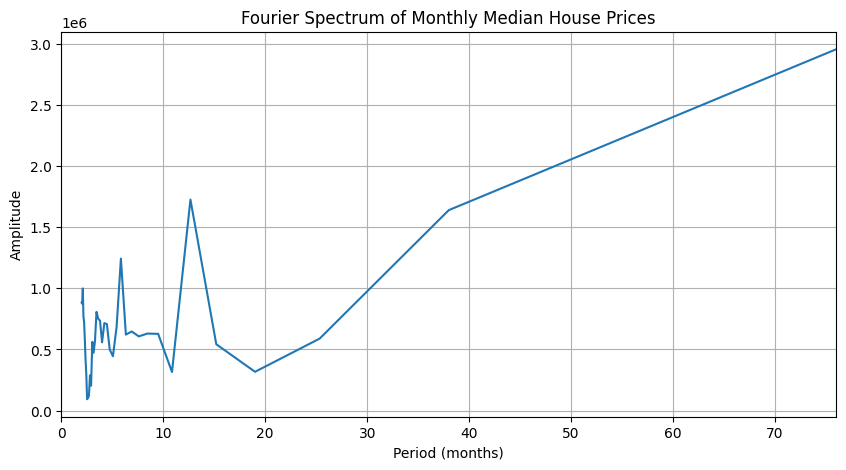

In [14]:
# Aggregate to monthly median sale price
monthly = (
    df.set_index("date_listed")["sold_price"]
    .resample("MS")
    .median()
    .dropna()
)

# Remove the linear trend
x = np.arange(len(monthly))
detrended = monthly.values - np.polyval(
    np.polyfit(x, monthly.values, 1), x
)

# Fourier transform
fft = np.fft.rfft(detrended)
freq = np.fft.rfftfreq(len(detrended), d=1)  # cycles per month
amplitude = np.abs(fft)

# Convert frequency to period in months; exclude zero frequency
period = np.divide(
    1, freq[1:], out=np.full_like(freq[1:], np.inf), where=freq[1:] != 0
)

# Visualize the frequency spectrum
plt.figure(figsize=(10, 5))
plt.plot(period, amplitude[1:])
plt.xlabel("Period (months)")
plt.ylabel("Amplitude")
plt.title("Fourier Spectrum of Monthly Median House Prices")
plt.xlim(0, len(monthly))
plt.grid(True)
plt.show()

#### What the Heck does this Fourier Transform Mean:
- Peak at 12 months mean strong annual seasonal cycle
- peak at 6 months reflect some more sub cycles
- Dw too much about the stuff trending up past 20 months, that just means we don't have enough data.

### Scaling Stuff
#### How to Scale Stuff:
1. Pick a grouping (categorical feature)
2. Find the mean price over the training period for each level of said feature
3. Divide the overall mean by the mean price to get the factor (minus in log space)
4. Divide the sale price by style factor (minus in log space)
5. train a model to predict style_scale using style_offset. Overall Median is from the training data.
6. For prediction, multiply predicted trend by style factor?

#### How to Interpret the Scaled Factor Thing:
- scaled sold price log basically is sold price adjusted for the difference between median log sold prices for the various categories in the feature.
- the plot adjusted for this stuff should basically say "what variation and trends remain that are not accounted for by variation in this category".

#### Using this Stuff with Meta Model (stacking):
- Cross Validation. Each base model is trained on K-1 folds and predicts the Kth fold. This gives you predictions from base models that were not traing on said observations.
- Meta Model then trains on the predictions from said base models with the actual thing.

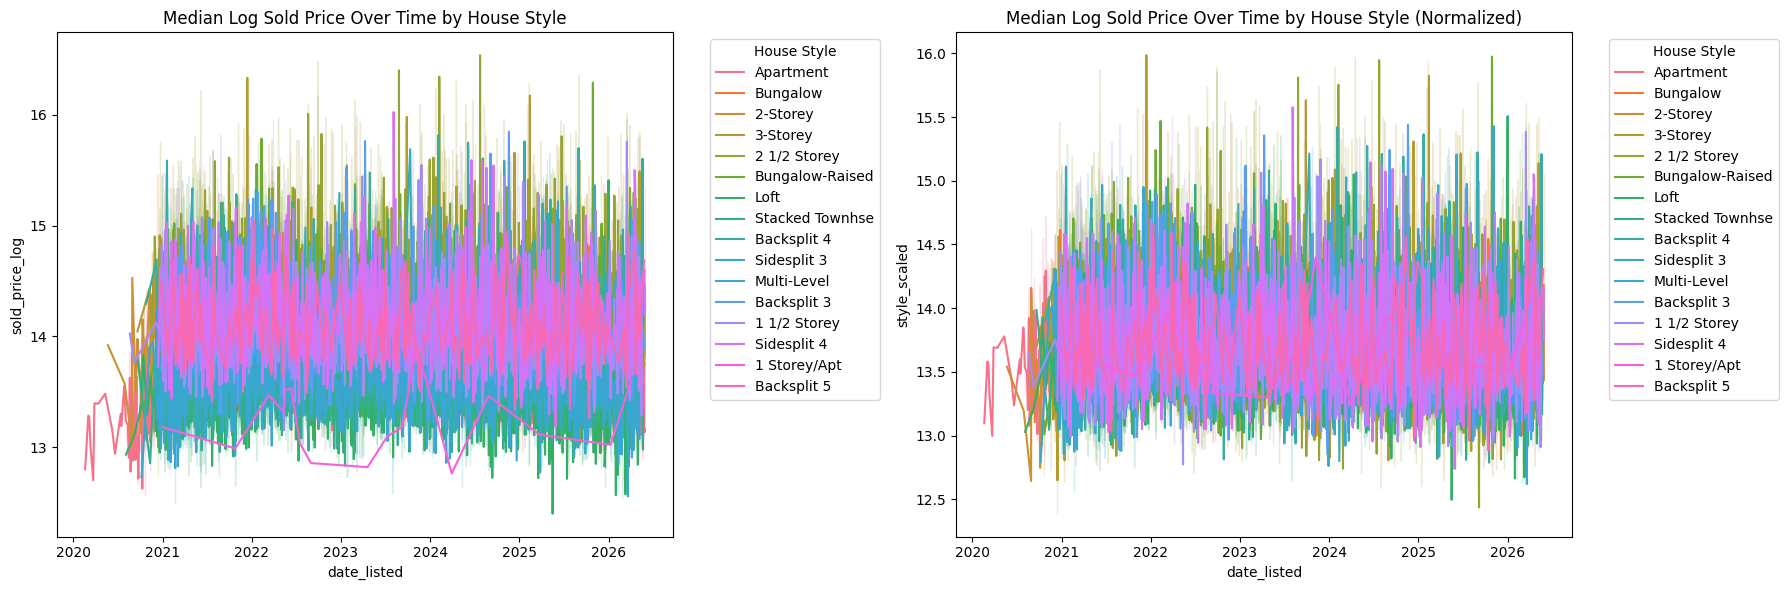

In [15]:
# Factors for House Style
house_style_data = df.groupby(['house_style'])['sold_price_log'].median().reset_index()
overall_median = df['sold_price_log'].median()
style_offset = df.groupby("house_style")["sold_price_log"].median() - overall_median
df["style_scaled"] = df["sold_price_log"] - df["house_style"].map(style_offset)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes = axes.flatten()

sns.lineplot(x=df["date_listed"], y=df["sold_price_log"], hue=df["house_style"], ax=axes[0])
axes[0].set_title("Median Log Sold Price Over Time by House Style")
axes[0].legend(title="House Style", bbox_to_anchor=(1.05, 1))
sns.lineplot(x=df["date_listed"], y=df["style_scaled"], hue=df["house_style"], ax=axes[1])
axes[1].set_title("Median Log Sold Price Over Time by House Style (Normalized)")
axes[1].legend(title="House Style", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

KeyboardInterrupt: 

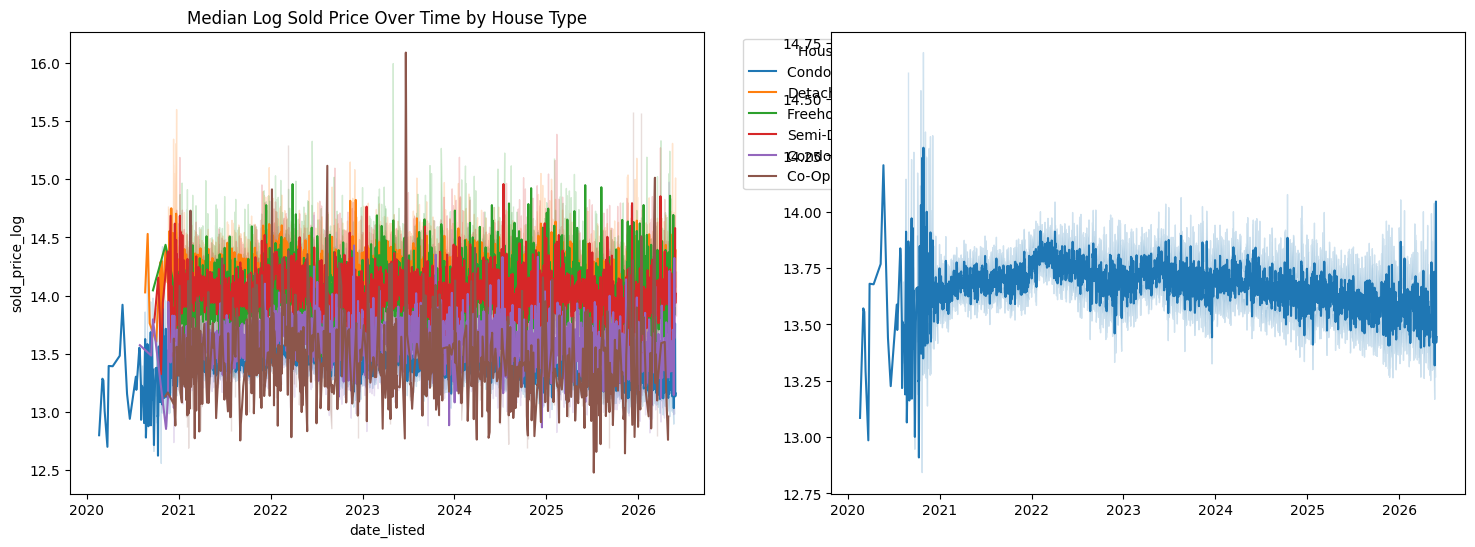

In [16]:
# Factors for House Type
house_style_data = df.groupby(['house_type_name'])['sold_price_log'].median().reset_index()
overall_median = df['sold_price_log'].median()
style_offset = df.groupby("house_type_name")["sold_price_log"].median() - overall_median
df["house_type_name_scaled"] = df["sold_price_log"] - df["house_type_name"].map(style_offset)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes = axes.flatten()

sns.lineplot(x=df["date_listed"], y=df["sold_price_log"], hue=df["house_type_name"], ax=axes[0])
axes[0].set_title("Median Log Sold Price Over Time by House Type")
axes[0].legend(title="House Type", bbox_to_anchor=(1.05, 1))
sns.lineplot(x=df["date_listed"], y=df["house_type_name_scaled"], hue=df["house_type_name"], ax=axes[1])
axes[1].set_title("Median Log Sold Price Over Time by House Type (Normalized)")
axes[1].legend(title="House Type", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

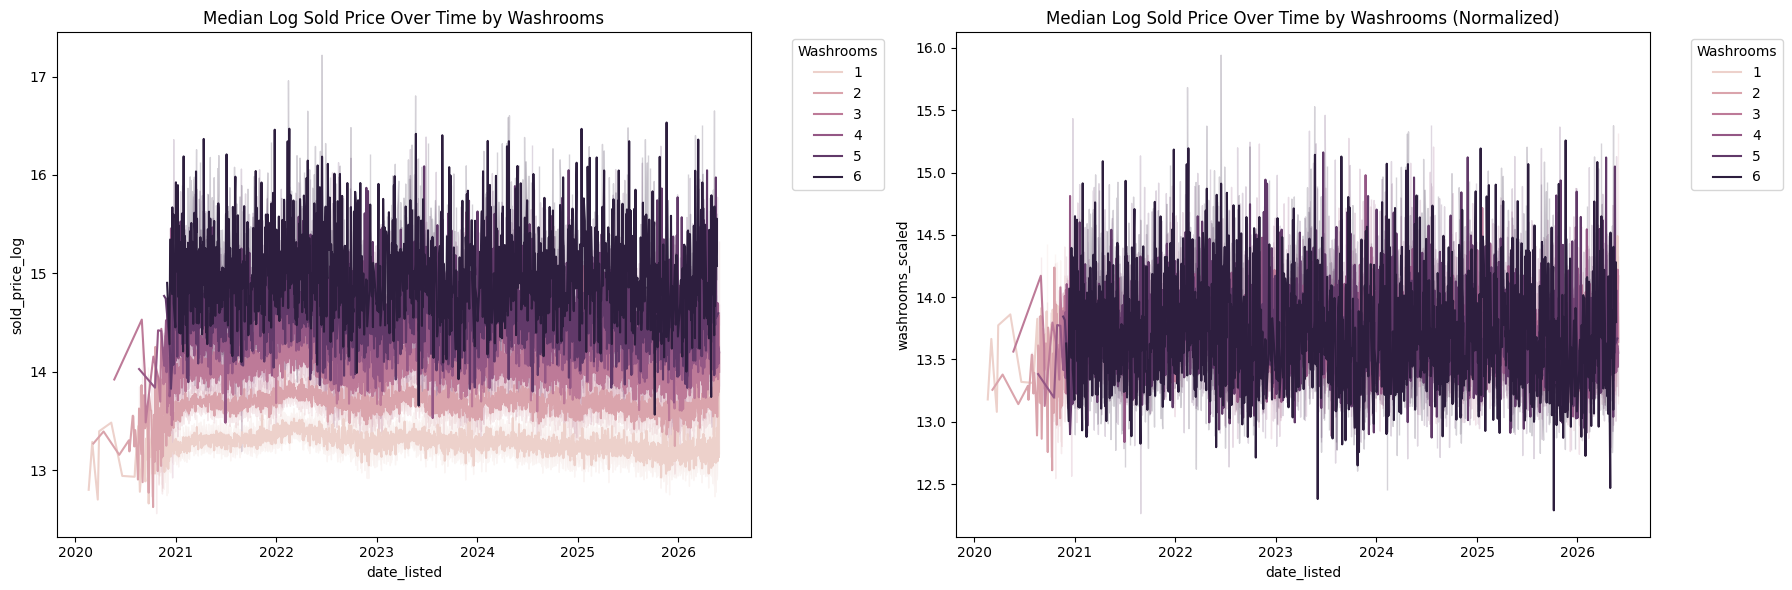

In [ ]:
# Factors for Washrooms
house_style_data = df.groupby(['washrooms'])['sold_price_log'].median().reset_index()
overall_median = df['sold_price_log'].median()
style_offset = df.groupby("washrooms")["sold_price_log"].median() - overall_median
df["washrooms_scaled"] = df["sold_price_log"] - df["washrooms"].map(style_offset)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes = axes.flatten()

sns.lineplot(x=df["date_listed"], y=df["sold_price_log"], hue=df["washrooms"], ax=axes[0])
axes[0].set_title("Median Log Sold Price Over Time by Washrooms")
axes[0].legend(title="Washrooms", bbox_to_anchor=(1.05, 1))
sns.lineplot(x=df["date_listed"], y=df["washrooms_scaled"], hue=df["washrooms"], ax=axes[1])
axes[1].set_title("Median Log Sold Price Over Time by Washrooms (Normalized)")
axes[1].legend(title="Washrooms", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

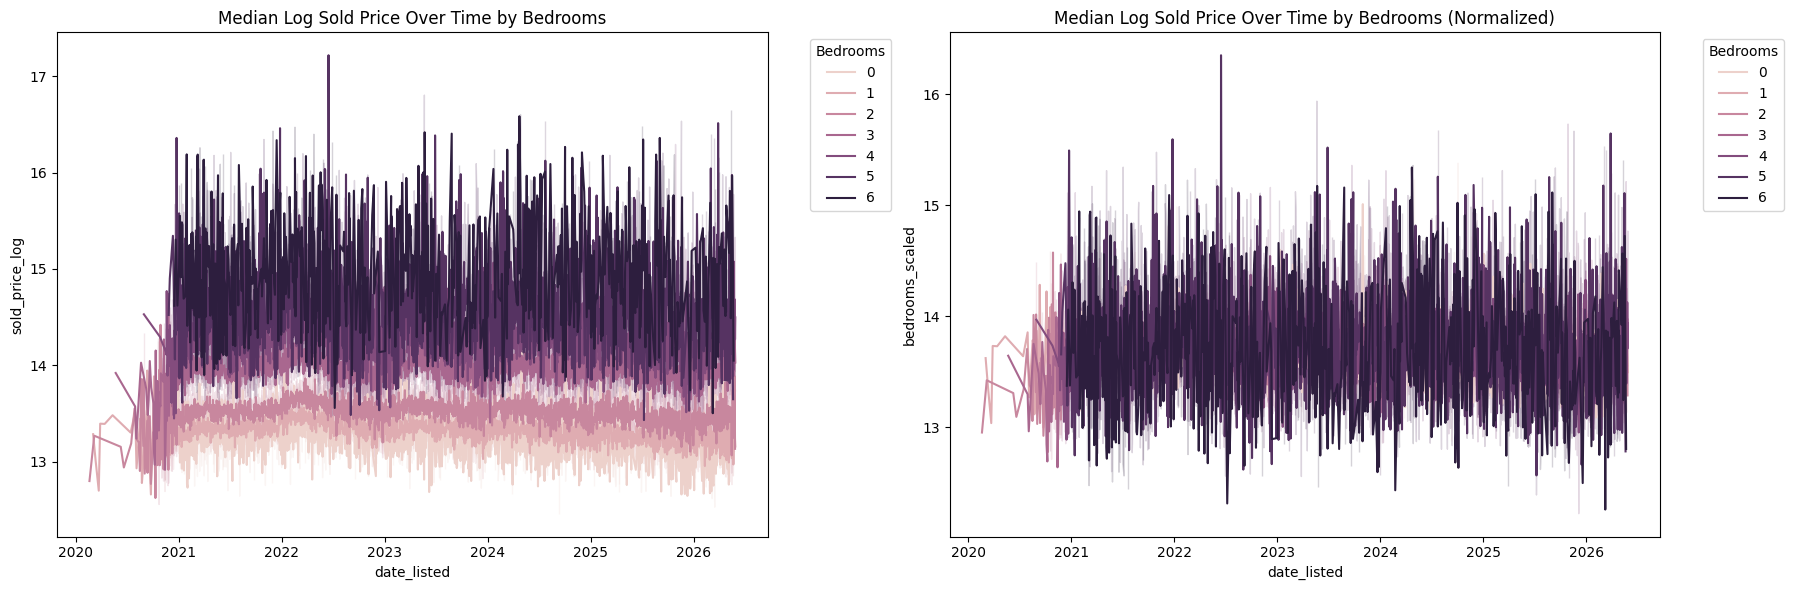

In [ ]:
# Factors for Bedrooms
house_style_data = df.groupby(['bedrooms'])['sold_price_log'].median().reset_index()
overall_median = df['sold_price_log'].median()
style_offset = df.groupby("bedrooms")["sold_price_log"].median() - overall_median
df["bedrooms_scaled"] = df["sold_price_log"] - df["bedrooms"].map(style_offset)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes = axes.flatten()

sns.lineplot(x=df["date_listed"], y=df["sold_price_log"], hue=df["bedrooms"], ax=axes[0])
axes[0].set_title("Median Log Sold Price Over Time by Bedrooms")
axes[0].legend(title="Bedrooms", bbox_to_anchor=(1.05, 1))
sns.lineplot(x=df["date_listed"], y=df["bedrooms_scaled"], hue=df["bedrooms"], ax=axes[1])
axes[1].set_title("Median Log Sold Price Over Time by Bedrooms (Normalized)")
axes[1].legend(title="Bedrooms", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [ ]:
# Factors for Community
house_style_data = df.groupby(['community'])['sold_price_log'].median().reset_index()
overall_median = df['sold_price_log'].median()
style_offset = df.groupby("community")["sold_price_log"].median() - overall_median
df["community_scaled"] = df["sold_price_log"] - df["community"].map(style_offset)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes = axes.flatten()

sns.lineplot(x=df["date_listed"], y=df["sold_price_log"], hue=df["community"], ax=axes[0])
axes[0].set_title("Median Log Sold Price Over Time by Community")
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(title="Community", bbox_to_anchor=(1.05, 1), handles=handles[:10], labels=labels[:10])
sns.lineplot(x=df["date_listed"], y=df["community_scaled"], hue=df["community"], ax=axes[1])
axes[1].set_title("Median Log Sold Price Over Time by Community (Normalized)")
handles, labels = axes[1].get_legend_handles_labels()
axes[1].legend(title="Community", bbox_to_anchor=(1.05, 1), handles=handles[:10], labels=labels[:10])
plt.tight_layout()
plt.show()

NameError: name 'df' is not defined

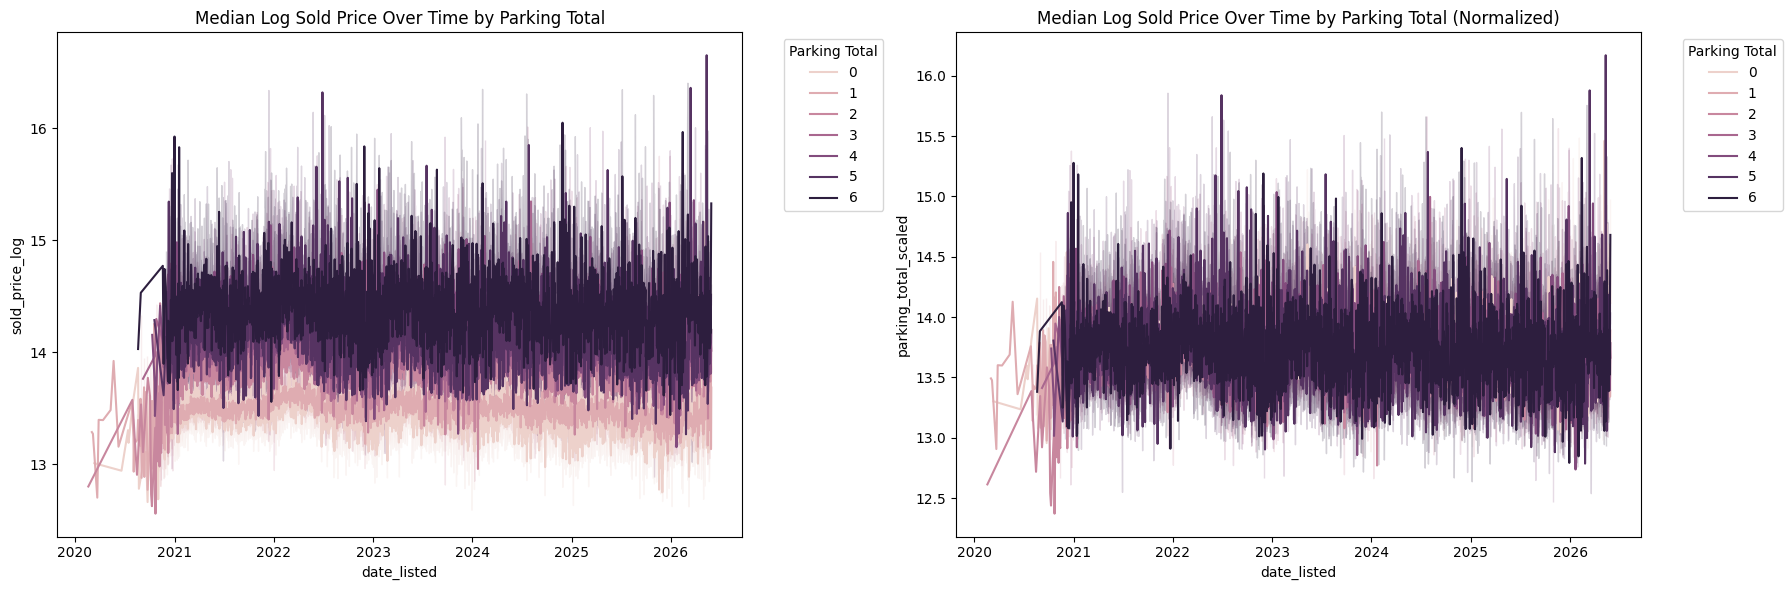

In [ ]:
# Factors for Parking Total
house_style_data = df.groupby(['parking_total'])['sold_price_log'].median().reset_index()
overall_median = df['sold_price_log'].median()
style_offset = df.groupby("parking_total")["sold_price_log"].median() - overall_median
df["parking_total_scaled"] = df["sold_price_log"] - df["parking_total"].map(style_offset)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes = axes.flatten()


sns.lineplot(x=df["date_listed"], y=df["sold_price_log"], hue=df["parking_total"], ax=axes[0])
axes[0].set_title("Median Log Sold Price Over Time by Parking Total")
axes[0].legend(title="Parking Total", bbox_to_anchor=(1.05, 1))
sns.lineplot(x=df["date_listed"], y=df["parking_total_scaled"], hue=df["parking_total"], ax=axes[1])
axes[1].set_title("Median Log Sold Price Over Time by Parking Total (Normalized)")
axes[1].legend(title="Parking Total", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

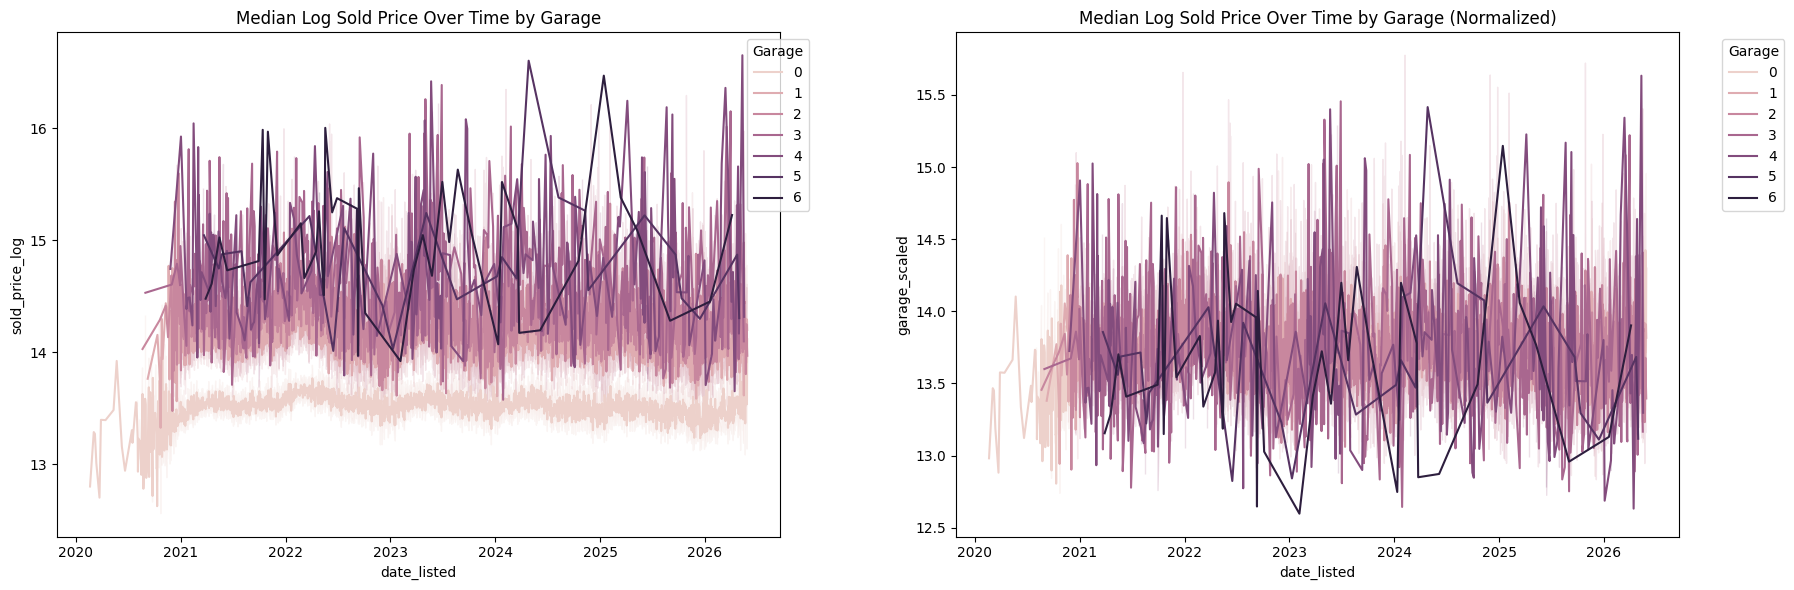

In [ ]:
# Factors for Garage
house_style_data = df.groupby(['garage'])['sold_price_log'].median().reset_index()
overall_median = df['sold_price_log'].median()
style_offset = df.groupby("garage")["sold_price_log"].median() - overall_median
df["garage_scaled"] = df["sold_price_log"] - df["garage"].map(style_offset)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes = axes.flatten()

sns.lineplot(x=df["date_listed"], y=df["sold_price_log"], hue=df["garage"], ax=axes[0])
axes[0].set_title("Median Log Sold Price Over Time by Garage")
axes[0].legend(title="Garage", bbox_to_anchor=(1.05, 1))
sns.lineplot(x=df["date_listed"], y=df["garage_scaled"], hue=df["garage"], ax=axes[1])
axes[1].set_title("Median Log Sold Price Over Time by Garage (Normalized)")
axes[1].legend(title="Garage", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

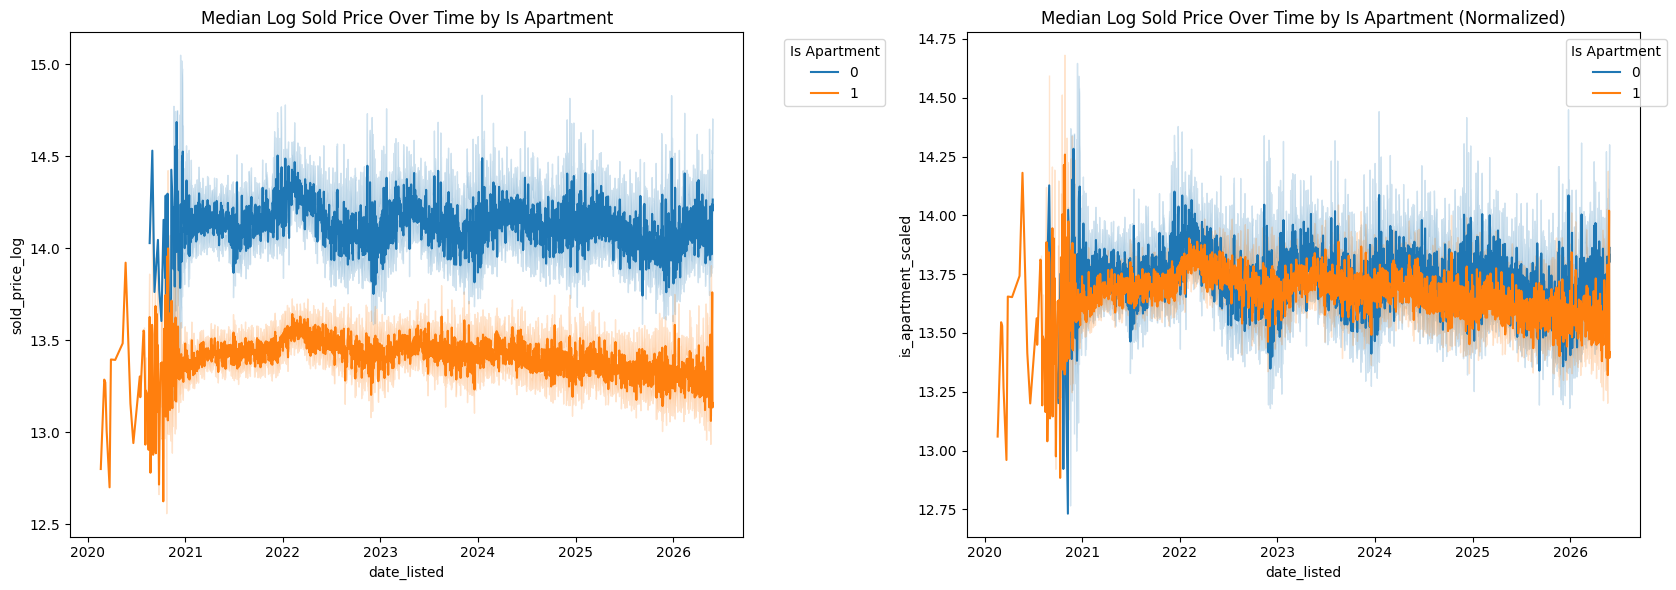

In [ ]:
# Factors for Is Apartment
house_style_data = df.groupby(['is_apartment'])['sold_price_log'].median().reset_index()
overall_median = df['sold_price_log'].median()
style_offset = df.groupby("is_apartment")["sold_price_log"].median() - overall_median
df["is_apartment_scaled"] = df["sold_price_log"] - df["is_apartment"].map(style_offset)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
axes = axes.flatten()

sns.lineplot(x=df["date_listed"], y=df["sold_price_log"], hue=df["is_apartment"], ax=axes[0])
axes[0].set_title("Median Log Sold Price Over Time by Is Apartment")
axes[0].legend(title="Is Apartment", bbox_to_anchor=(1.05, 1))
sns.lineplot(x=df["date_listed"], y=df["is_apartment_scaled"], hue=df["is_apartment"], ax=axes[1])
axes[1].set_title("Median Log Sold Price Over Time by Is Apartment (Normalized)")
axes[1].legend(title="Is Apartment", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

## Investigating Time Series Trends in Sales Price

### Sationarity

In [21]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
import data

df = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

df["month"] = df["date_listed"].dt.month
df["year"] = df["date_listed"].dt.year
df["day"] = df["date_listed"].dt.day
df["days_since_2021"] = (df["date_listed"] - pd.Timestamp("2021-01-01")).dt.days

time_features = ['month', 'year', 'day', 'days_since_2021']

In [35]:
off_market.columns

Index(['ml_num', 'date_listed', 'house_type_name', 'house_style', 'bedrooms',
       'washrooms', 'parking_total', 'garage', 'house_area', 'lot_front',
       'lot_depth', 'municipality', 'community', 'latitude', 'longitude',
       'remarks'],
      dtype='object')

Index(['ml_num', 'sold_price', 'list_price', 'date_listed', 'date_sold',
       'days_on_market', 'house_type_name', 'house_style', 'bedrooms',
       'washrooms', 'parking_total', 'garage', 'house_area', 'lot_front',
       'lot_depth', 'municipality', 'community', 'latitude', 'longitude',
       'external_avm_estimate', 'external_avm_estimate_date', 'remarks',
       'month', 'year', 'day', 'days_since_2021', 'log_sold_price'],
      dtype='object')

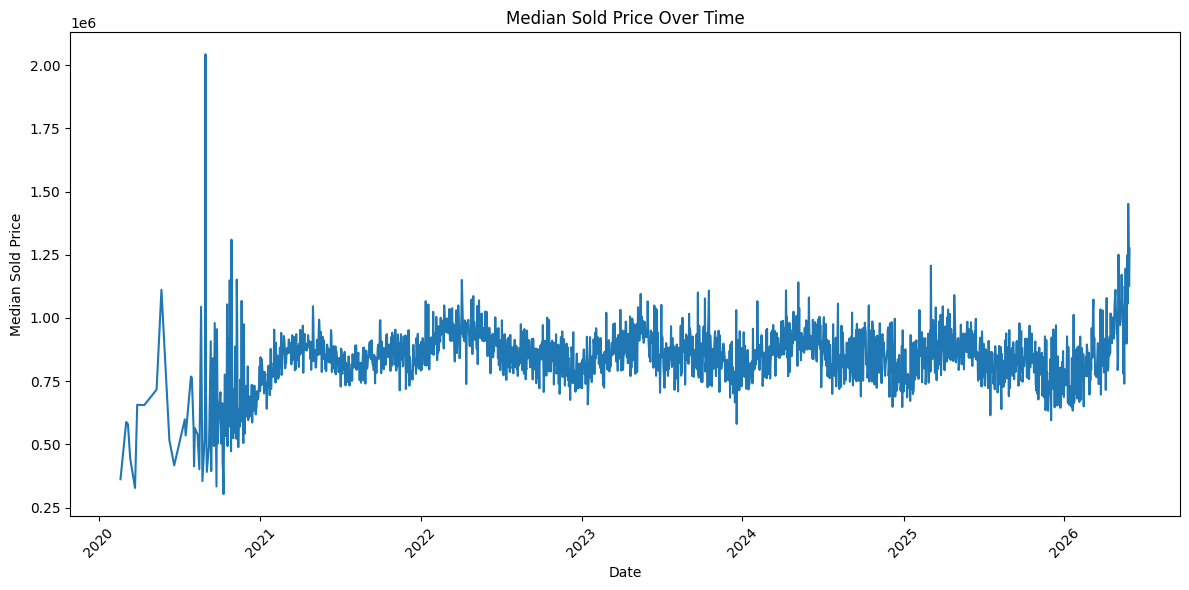

In [32]:
daily_median = df.groupby(df["date_listed"])["sold_price"].median()

plt.figure(figsize=(12, 6))
plt.plot(daily_median.index, daily_median.values)
plt.xlabel("Date")
plt.ylabel("Median Sold Price")
plt.title("Median Sold Price Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [33]:
# kpss test for whether the sold price is stationary
import statsmodels.api as sm

kpss_stat, p_val, lags, crit_vals = sm.tsa.stattools.kpss(daily_median.values)
print(f"KPSS Statistic: {kpss_stat}")
print(f"P-value: {p_val}")
print(f"Number of Lags: {lags}")
print(f"Critical Values: {crit_vals}")

KPSS Statistic: 0.6965784015847923
P-value: 0.013856508946837058
Number of Lags: 25
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}


#### Is this Thing Stationary
- from kpss test, the p value is < 0.05 which means the time series is not stationary